In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
from dask.diagnostics import ProgressBar
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.data_processing.load_data import ClimateModelData
from cordex2energy.utils.constants import EXTENT_CH, EXTENT_BC_MRRO, EXTENT_PREVAH
from cordex2energy.utils.utils_xarray import sel_extent

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

In [4]:
dask.config.set(num_workers=10)
dask.config.set({"array.chunk-size": "500MiB"})


os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set({"logging.distributed": "error"})
dask.config.set(num_workers=16, threads_per_worker=16)
dask.config.set({"array.chunk-size": "400MiB"})

dask.config.set({'distributed.worker.memory.target': 0.75})  # Spill to disk at 75% usage
dask.config.set({'distributed.worker.memory.spill': 0.8})   # Start spilling at 80%
dask.config.set({'distributed.worker.memory.pause': 0.9})   # Pause worker at 90%

# Precipitation

In [5]:
climate_model_chains = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
]
climate_scenarios = ["rcp26", "rcp85"]

# Load precipitation data for all climate model chains and scenarios
ds_pr_dict = {}
for climate_model_chain in climate_model_chains:
    ds_pr_dict[climate_model_chain] = {}
    for scenario in climate_scenarios:
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{scenario}"
            / "bias_corrected"
        )

        ds_pr = ClimateModelData(
            bias_corrected_dir / "day" / "pr.zarr",
            chunks="auto",
            extent=EXTENT_CH
        )

        ds_pr.ds_data = ds_pr.ds_data.sel(time=slice("1991", "2020"))
        ds_pr_dict[climate_model_chain][scenario] = ds_pr

In [6]:
ds_tp = sel_extent(xr.open_zarr(path_data_processed / "cerra_processed" / "regridded" / "tp.zarr", chunks="auto"), extent=EXTENT_CH).sel(time=slice("1991", "2020"))

In [7]:
path_meteoswiss = Path("/net/atmos/data/MeteoCH_gridded/")
ds_rhires = xr.open_mfdataset((path_meteoswiss / "ch01" / "RhiresD").glob("*.nc"), chunks="auto").sel(time=slice("1991", "2020"))

In [17]:
path_era5 = Path(paths["path_data_cerra"]).parent / "era5-land_cds"
paths_era5_tp = (path_era5 / "processed/v1/tp/day/native").glob("*.nc")
ds_era5_tp = sel_extent(xr.open_mfdataset(paths_era5_tp, chunks="auto"), EXTENT_CH).sel(time=slice("1991", "2020"))
ds_era5_tp["tp"] = ds_era5_tp["tp"] * 1000  # Convert from m to mm

In [21]:
# Compute spatial means for CERRA and RhiresD (common to all subplots)
tp_daily_mean = ds_tp['tp'].mean(dim=['lat', 'lon'])
rhires_daily_mean = ds_rhires['RhiresD'].mean(dim=['E', 'N'])
era5_tp_daily_mean = ds_era5_tp['tp'].mean(dim=['lat', 'lon'])

# Compute monthly means for CERRA and RhiresD
tp_monthly_mean = tp_daily_mean.groupby('time.month').mean()
rhires_monthly_mean = rhires_daily_mean.groupby('time.month').mean()
era5_tp_monthly_mean = era5_tp_daily_mean.groupby('time.month').mean()

# Compute with progress bar
with ProgressBar():
    tp_monthly_mean = tp_monthly_mean.compute()
    rhires_monthly_mean = rhires_monthly_mean.compute()
    era5_tp_monthly_mean = era5_tp_monthly_mean.compute()

# Compute monthly means for each climate model chain and scenario
pr_monthly_means = {}
for climate_model_chain in climate_model_chains:
    pr_monthly_means[climate_model_chain] = {}
    for scenario in climate_scenarios:
        ds_pr = ds_pr_dict[climate_model_chain][scenario]
        pr_daily_mean = ds_pr.ds_data['pr'].mean(dim=['lat', 'lon'])
        pr_monthly_mean = pr_daily_mean.groupby('time.month').mean()

        with ProgressBar():
            pr_monthly_means[climate_model_chain][scenario] = pr_monthly_mean.compute()

[########################################] | 100% Completed | 9.35 sms
[########################################] | 100% Completed | 147.83 s
[########################################] | 100% Completed | 440.10 s
[########################################] | 100% Completed | 29.97 s
[########################################] | 100% Completed | 28.42 s
[########################################] | 100% Completed | 26.77 s
[########################################] | 100% Completed | 26.32 s
[########################################] | 100% Completed | 25.61 s
[########################################] | 100% Completed | 45.86 s


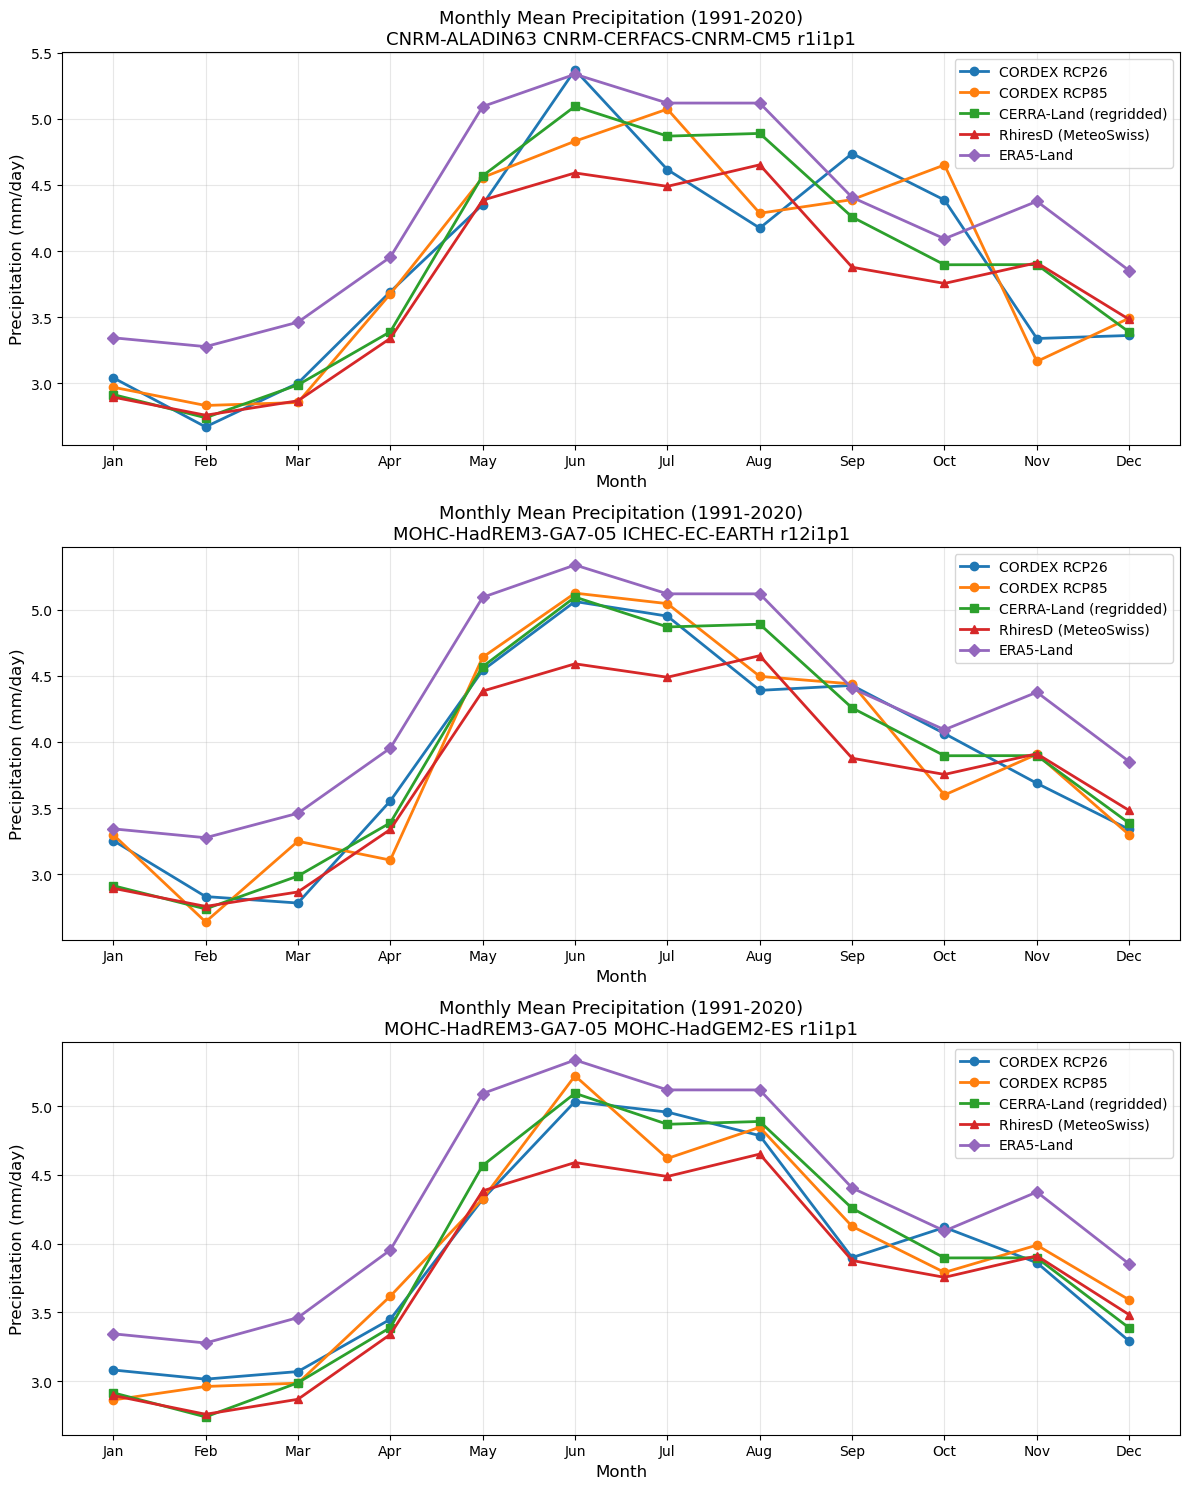

In [22]:
# Create subplots for each climate model chain
fig, axes = plt.subplots(len(climate_model_chains), 1, figsize=(12, 5 * len(climate_model_chains)))

# If only one chain, axes is not a list
if len(climate_model_chains) == 1:
    axes = [axes]

for idx, climate_model_chain in enumerate(climate_model_chains):
    ax = axes[idx]

    # Plot the monthly means for each scenario
    for scenario in climate_scenarios:
        ax.plot(pr_monthly_means[climate_model_chain][scenario].month,
                pr_monthly_means[climate_model_chain][scenario],
                marker='o', label=f'CORDEX {scenario.upper()}', linewidth=2, markersize=6)

    ax.plot(tp_monthly_mean.month, tp_monthly_mean,
            marker='s', label='CERRA-Land (regridded)', linewidth=2, markersize=6)
    ax.plot(rhires_monthly_mean.month, rhires_monthly_mean,
            marker='^', label='RhiresD (MeteoSwiss)', linewidth=2, markersize=6)
    ax.plot(era5_tp_monthly_mean.month, era5_tp_monthly_mean,
            marker='D', label='ERA5-Land', linewidth=2, markersize=6)

    ax.set_xlabel('Month', fontsize=12)
    ax.set_ylabel('Precipitation (mm/day)', fontsize=12)

    # Format the chain name for the title
    chain_name = climate_model_chain.replace('_', ' ')
    ax.set_title(f'Monthly Mean Precipitation (1991-2020)\n{chain_name}', fontsize=13)

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                        'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

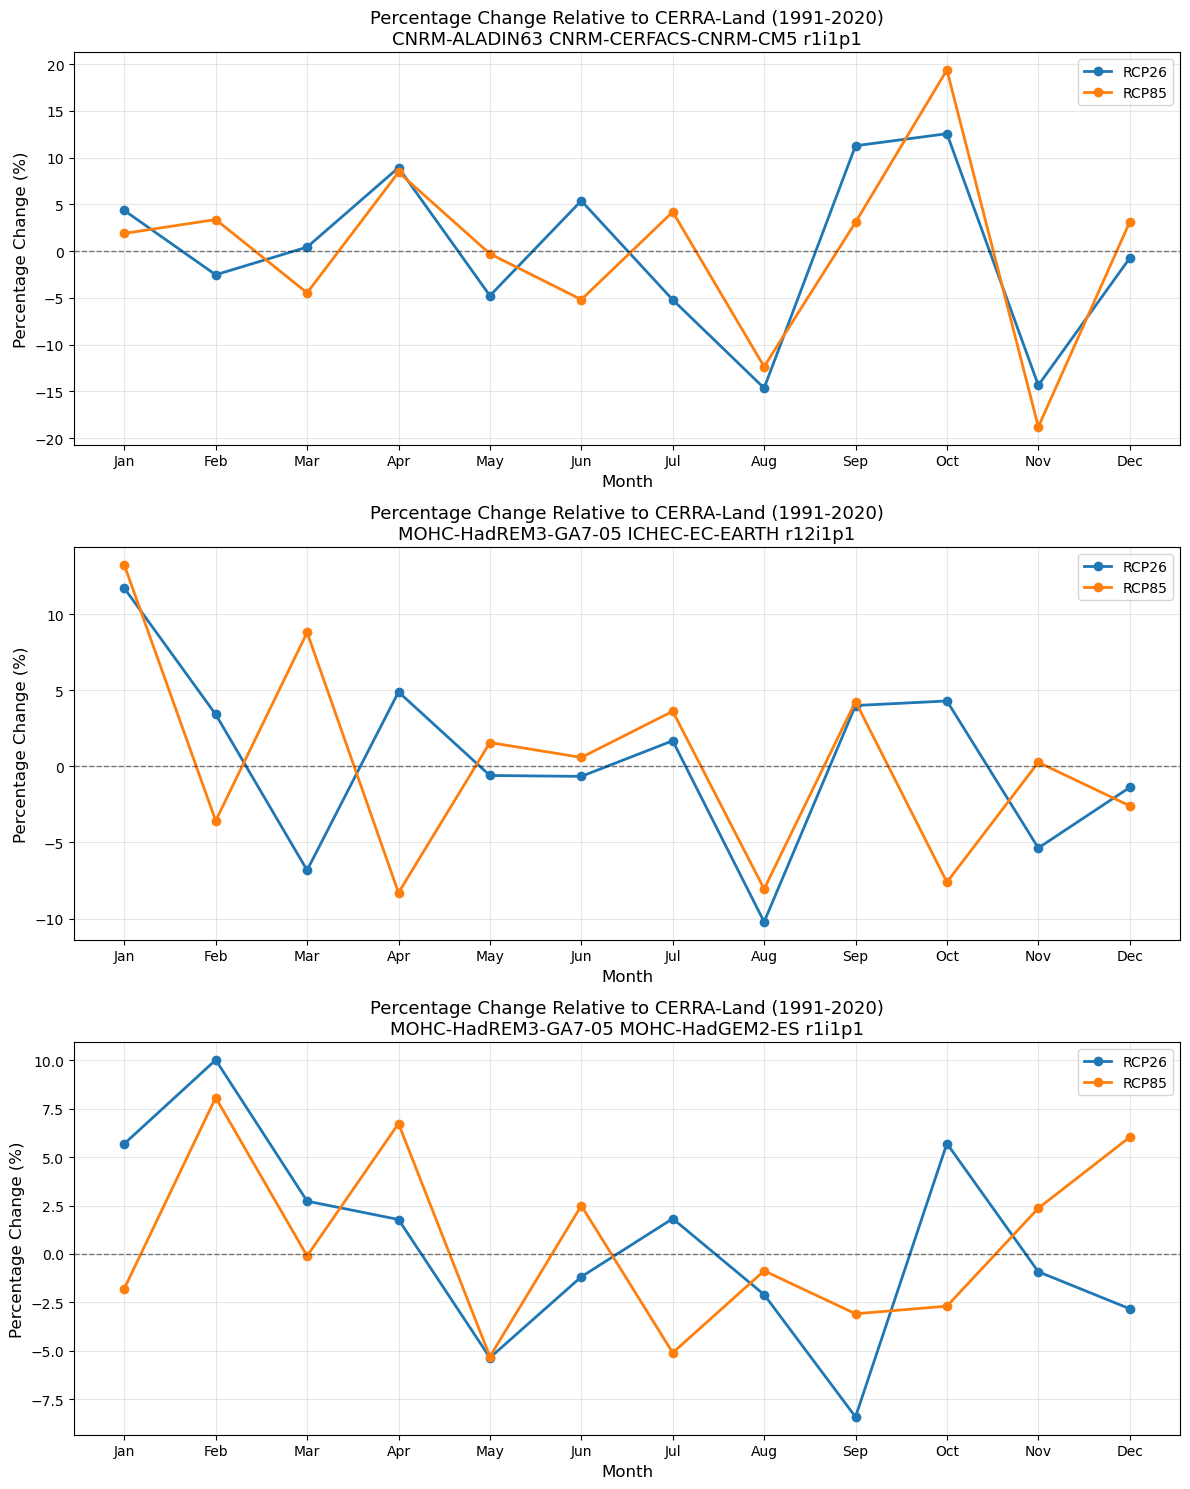

In [10]:
# Compute percentage change of each climate model relative to CERRA
percentage_changes = {}
for climate_model_chain in climate_model_chains:
    percentage_changes[climate_model_chain] = {}
    for scenario in climate_scenarios:
        pr_model = pr_monthly_means[climate_model_chain][scenario]
        percentage_change = ((pr_model - tp_monthly_mean) / tp_monthly_mean) * 100
        percentage_changes[climate_model_chain][scenario] = percentage_change

# Create subplots for each climate model chain showing percentage change
fig, axes = plt.subplots(len(climate_model_chains), 1, figsize=(12, 5 * len(climate_model_chains)))

if len(climate_model_chains) == 1:
    axes = [axes]

for idx, climate_model_chain in enumerate(climate_model_chains):
    ax = axes[idx]

    # Plot the percentage changes for each scenario
    for scenario in climate_scenarios:
        ax.plot(percentage_changes[climate_model_chain][scenario].month,
                percentage_changes[climate_model_chain][scenario],
                marker='o', label=f'{scenario.upper()}', linewidth=2, markersize=6)

    # Add horizontal line at 0%
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)

    ax.set_xlabel('Month', fontsize=12)
    ax.set_ylabel('Percentage Change (%)', fontsize=12)

    chain_name = climate_model_chain.replace('_', ' ')
    ax.set_title(f'Percentage Change Relative to CERRA-Land (1991-2020)\n{chain_name}', fontsize=13)

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                        'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Daily Climatology

In [ ]:
# Compute daily climatology (mean for each day of year) over the time period
tp_daily_climatology = ds_tp['tp'].groupby('time.dayofyear').mean(dim=['lat', 'lon', 'time'])
rhires_daily_climatology = ds_rhires['RhiresD'].groupby('time.dayofyear').mean(dim=['E', 'N', 'time'])

# Compute daily climatology for each climate model chain and scenario
pr_daily_climatology = {}
for climate_model_chain in climate_model_chains:
    pr_daily_climatology[climate_model_chain] = {}
    for scenario in climate_scenarios:
        ds_pr = ds_pr_dict[climate_model_chain][scenario]
        daily_clim = ds_pr.ds_data['pr'].groupby('time.dayofyear').mean(dim=['lat', 'lon', 'time'])
        pr_daily_climatology[climate_model_chain][scenario] = daily_clim

# Compute with progress bar
with ProgressBar():
    tp_daily_climatology = tp_daily_climatology.compute()
    rhires_daily_climatology = rhires_daily_climatology.compute()

    for climate_model_chain in climate_model_chains:
        for scenario in climate_scenarios:
            pr_daily_climatology[climate_model_chain][scenario] = pr_daily_climatology[climate_model_chain][scenario].compute()

print("Daily climatology computed successfully")

[########################################] | 100% Completed | 101.51 ms
[########################################] | 100% Completed | 2.12 sms
[########################################] | 100% Completed | 2.82 ss
[########################################] | 100% Completed | 707.68 ms
[########################################] | 100% Completed | 1.41 ss
[########################################] | 100% Completed | 808.50 ms
[########################################] | 100% Completed | 409.95 ms
[########################################] | 100% Completed | 412.14 ms
Daily climatology computed successfully


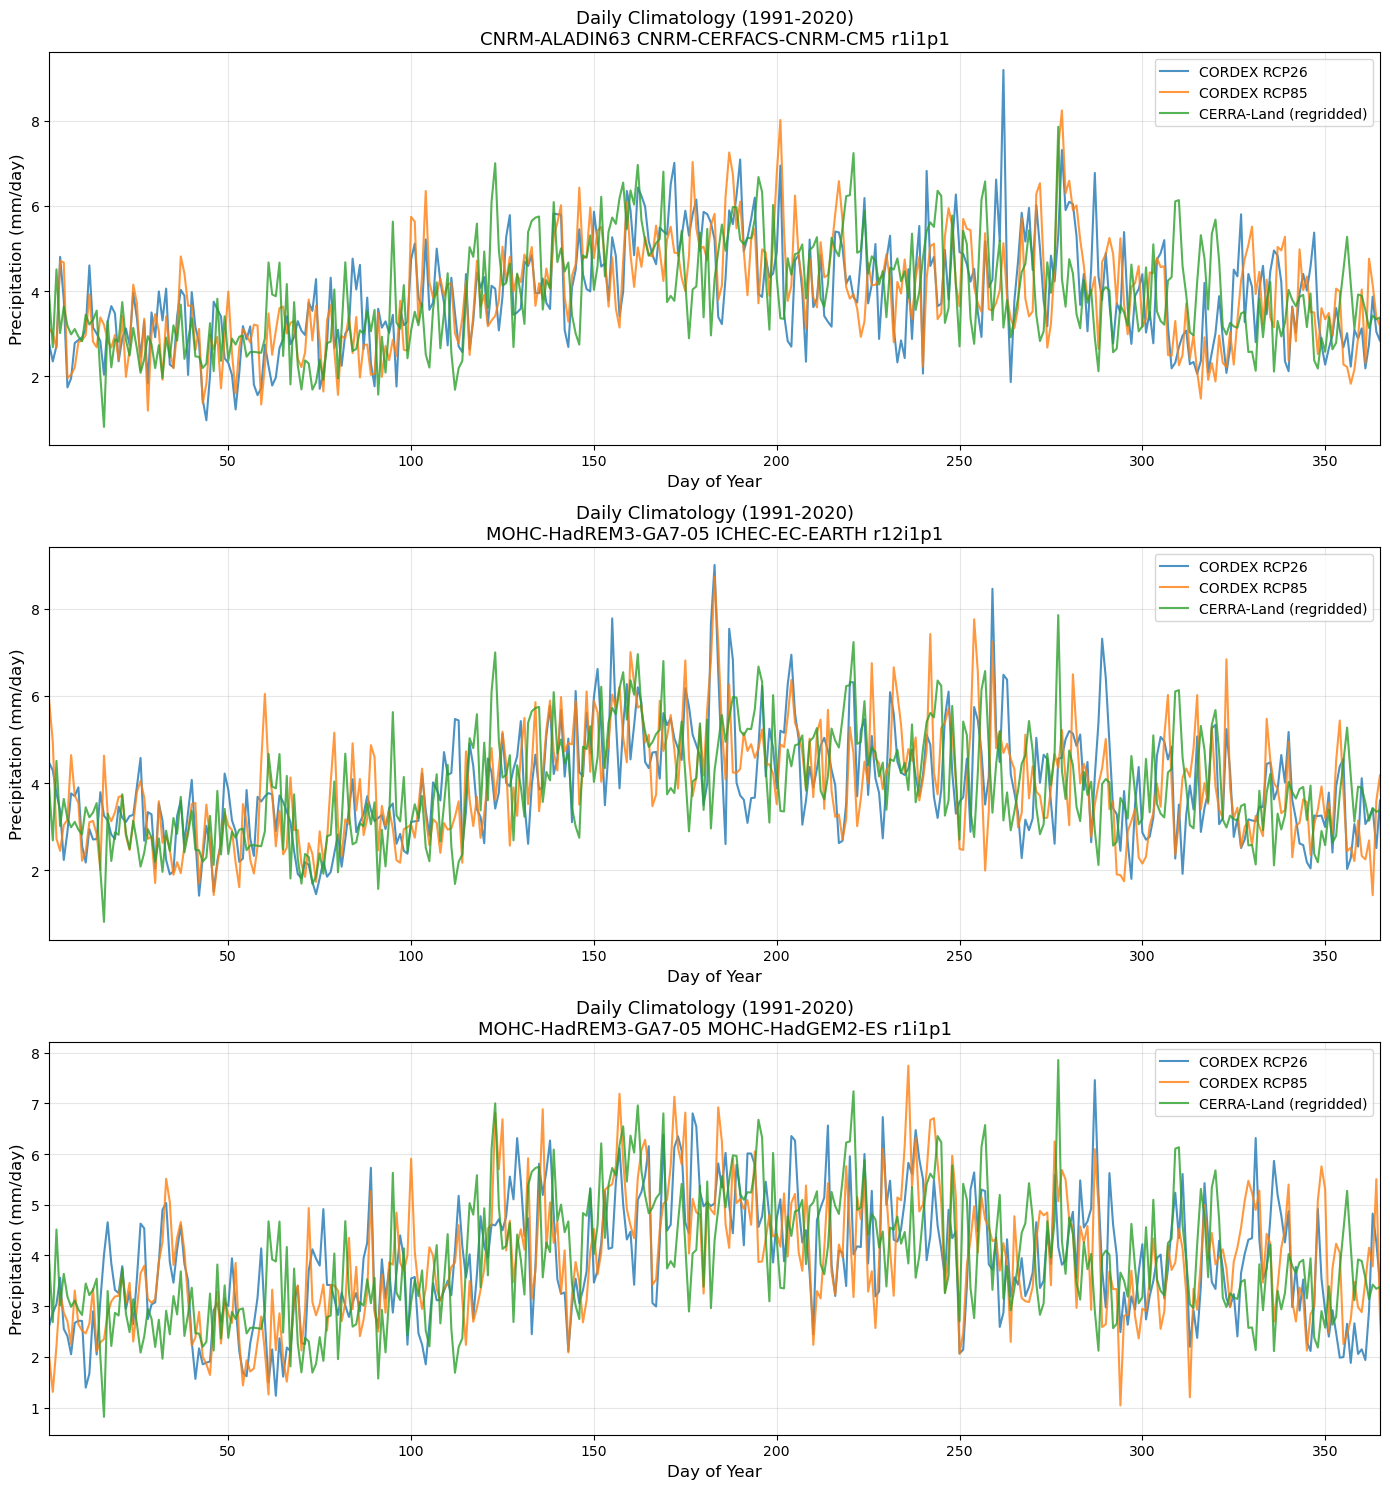

In [ ]:
# Plot daily climatology for each climate model chain
fig, axes = plt.subplots(len(climate_model_chains), 1, figsize=(14, 5 * len(climate_model_chains)))

if len(climate_model_chains) == 1:
    axes = [axes]

for idx, climate_model_chain in enumerate(climate_model_chains):
    ax = axes[idx]

    # Plot the daily climatology for each scenario
    for scenario in climate_scenarios:
        ax.plot(pr_daily_climatology[climate_model_chain][scenario].dayofyear,
                pr_daily_climatology[climate_model_chain][scenario],
                label=f'CORDEX {scenario.upper()}', linewidth=1.5, alpha=0.8)

    ax.plot(tp_daily_climatology.dayofyear, tp_daily_climatology,
            label='CERRA-Land (regridded)', linewidth=1.5, alpha=0.8)
    # ax.plot(rhires_daily_climatology.dayofyear, rhires_daily_climatology,
    #         label='RhiresD (MeteoSwiss)', linewidth=1.5, alpha=0.8)

    ax.set_xlabel('Day of Year', fontsize=12)
    ax.set_ylabel('Precipitation (mm/day)', fontsize=12)

    # Format the chain name for the title
    chain_name = climate_model_chain.replace('_', ' ')
    ax.set_title(f'Daily Climatology (1991-2020)\n{chain_name}', fontsize=13)

    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(1, 365)

plt.tight_layout()
plt.show()

# Temperature

In [5]:
climate_model_chains = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
]
climate_scenarios = ["rcp26", "rcp85"]

# Load precipitation data for all climate model chains and scenarios
ds_tas_dict = {}
for climate_model_chain in climate_model_chains:
    ds_tas_dict[climate_model_chain] = {}
    for scenario in climate_scenarios:
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{scenario}"
            / "bias_corrected"
        )

        ds_tas = ClimateModelData(
            bias_corrected_dir / "day" / "tas.zarr",
            chunks="auto",
            extent=EXTENT_CH
        )

        ds_tas.ds_data = ds_tas.ds_data.sel(time=slice("1991", "2020"))
        ds_tas_dict[climate_model_chain][scenario] = ds_tas

In [19]:
climate_model_chains = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
]
climate_scenarios = ["rcp26", "rcp85"]

# Load precipitation data for all climate model chains and scenarios
ds_tas_dict = {}
for climate_model_chain in climate_model_chains:
    ds_tas_dict[climate_model_chain] = {}
    for scenario in climate_scenarios:
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{scenario}"
            / "bias_corrected"
        )

        ds_tas = ClimateModelData(
            bias_corrected_dir / "day" / "tas.zarr",
            chunks="auto",
            extent=EXTENT_CH
        )

        ds_tas.ds_data = ds_tas.ds_data.sel(time=slice("2040", "2060"))
        ds_tas_dict[climate_model_chain][scenario] = ds_tas

# Compute monthly means for each climate model chain and scenario
tas_monthly_means = {}
for climate_model_chain in climate_model_chains:
    tas_monthly_means[climate_model_chain] = {}
    for scenario in climate_scenarios:
        ds_tas = ds_tas_dict[climate_model_chain][scenario]
        tas_daily_mean = ds_tas.ds_data['tas'].mean(dim=['lat', 'lon'])
        tas_monthly_mean = tas_daily_mean.resample(time='1MS').mean()

        with ProgressBar():
            tas_monthly_means[climate_model_chain][scenario] = tas_monthly_mean.compute()

[########################################] | 100% Completed | 405.56 ms
[########################################] | 100% Completed | 409.39 ms
[########################################] | 100% Completed | 8.55 ss
[########################################] | 100% Completed | 14.81 s
[########################################] | 100% Completed | 12.79 s
[########################################] | 100% Completed | 5.95 ss


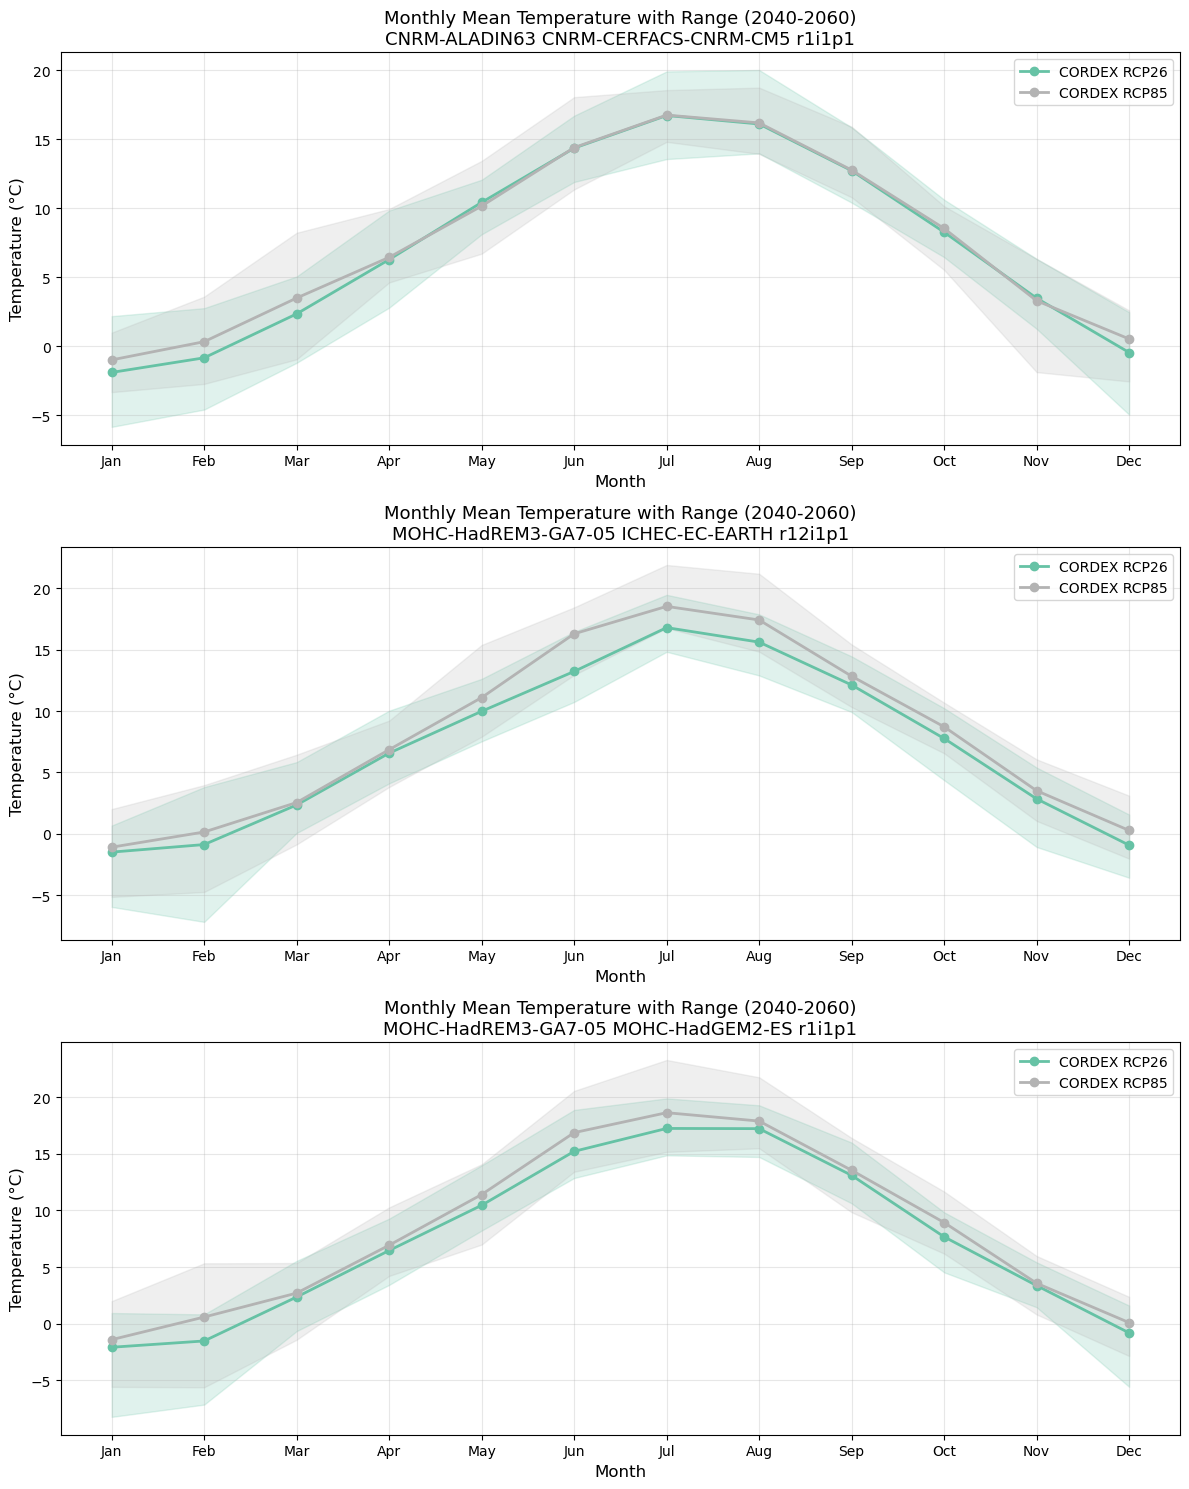

In [20]:
fig, axes = plt.subplots(len(climate_model_chains), 1, figsize=(12, 5 * len(climate_model_chains)))

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
if len(climate_model_chains) == 1:
    axes = [axes]

colors = plt.cm.Set2(np.linspace(0, 1, len(climate_scenarios)))

for idx, climate_model_chain in enumerate(climate_model_chains):
    ax = axes[idx]

    for scenario, color in zip(climate_scenarios, colors):
        ts = tas_monthly_means[climate_model_chain][scenario] - 273.15

        # Group by calendar month
        monthly_grouped = ts.groupby('time.month')
        monthly_mean = monthly_grouped.mean().values
        monthly_min = monthly_grouped.min().values
        monthly_max = monthly_grouped.max().values
        months = np.arange(1, 13)

        ax.plot(months, monthly_mean,
                marker='o', label=f'CORDEX {scenario.upper()}',
                linewidth=2, markersize=6, color=color)
        ax.fill_between(months, monthly_min, monthly_max,
                        alpha=0.2, color=color)

    ax.set_xlabel('Month', fontsize=12)
    ax.set_ylabel('Temperature (°C)', fontsize=12)
    chain_name = climate_model_chain.replace('_', ' ')
    ax.set_title(f'Monthly Mean Temperature with Range (2040-2060)\n{chain_name}', fontsize=13)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)
    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


[########################################] | 100% Completed | 510.21 ms
[########################################] | 100% Completed | 512.37 ms
[########################################] | 100% Completed | 707.13 ms
[########################################] | 100% Completed | 609.16 ms
[########################################] | 100% Completed | 608.02 ms
[########################################] | 100% Completed | 509.84 ms


/tmp/ipykernel_75109/2184342453.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(month_names)
/tmp/ipykernel_75109/2184342453.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(month_names)
/tmp/ipykernel_75109/2184342453.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(month_names)


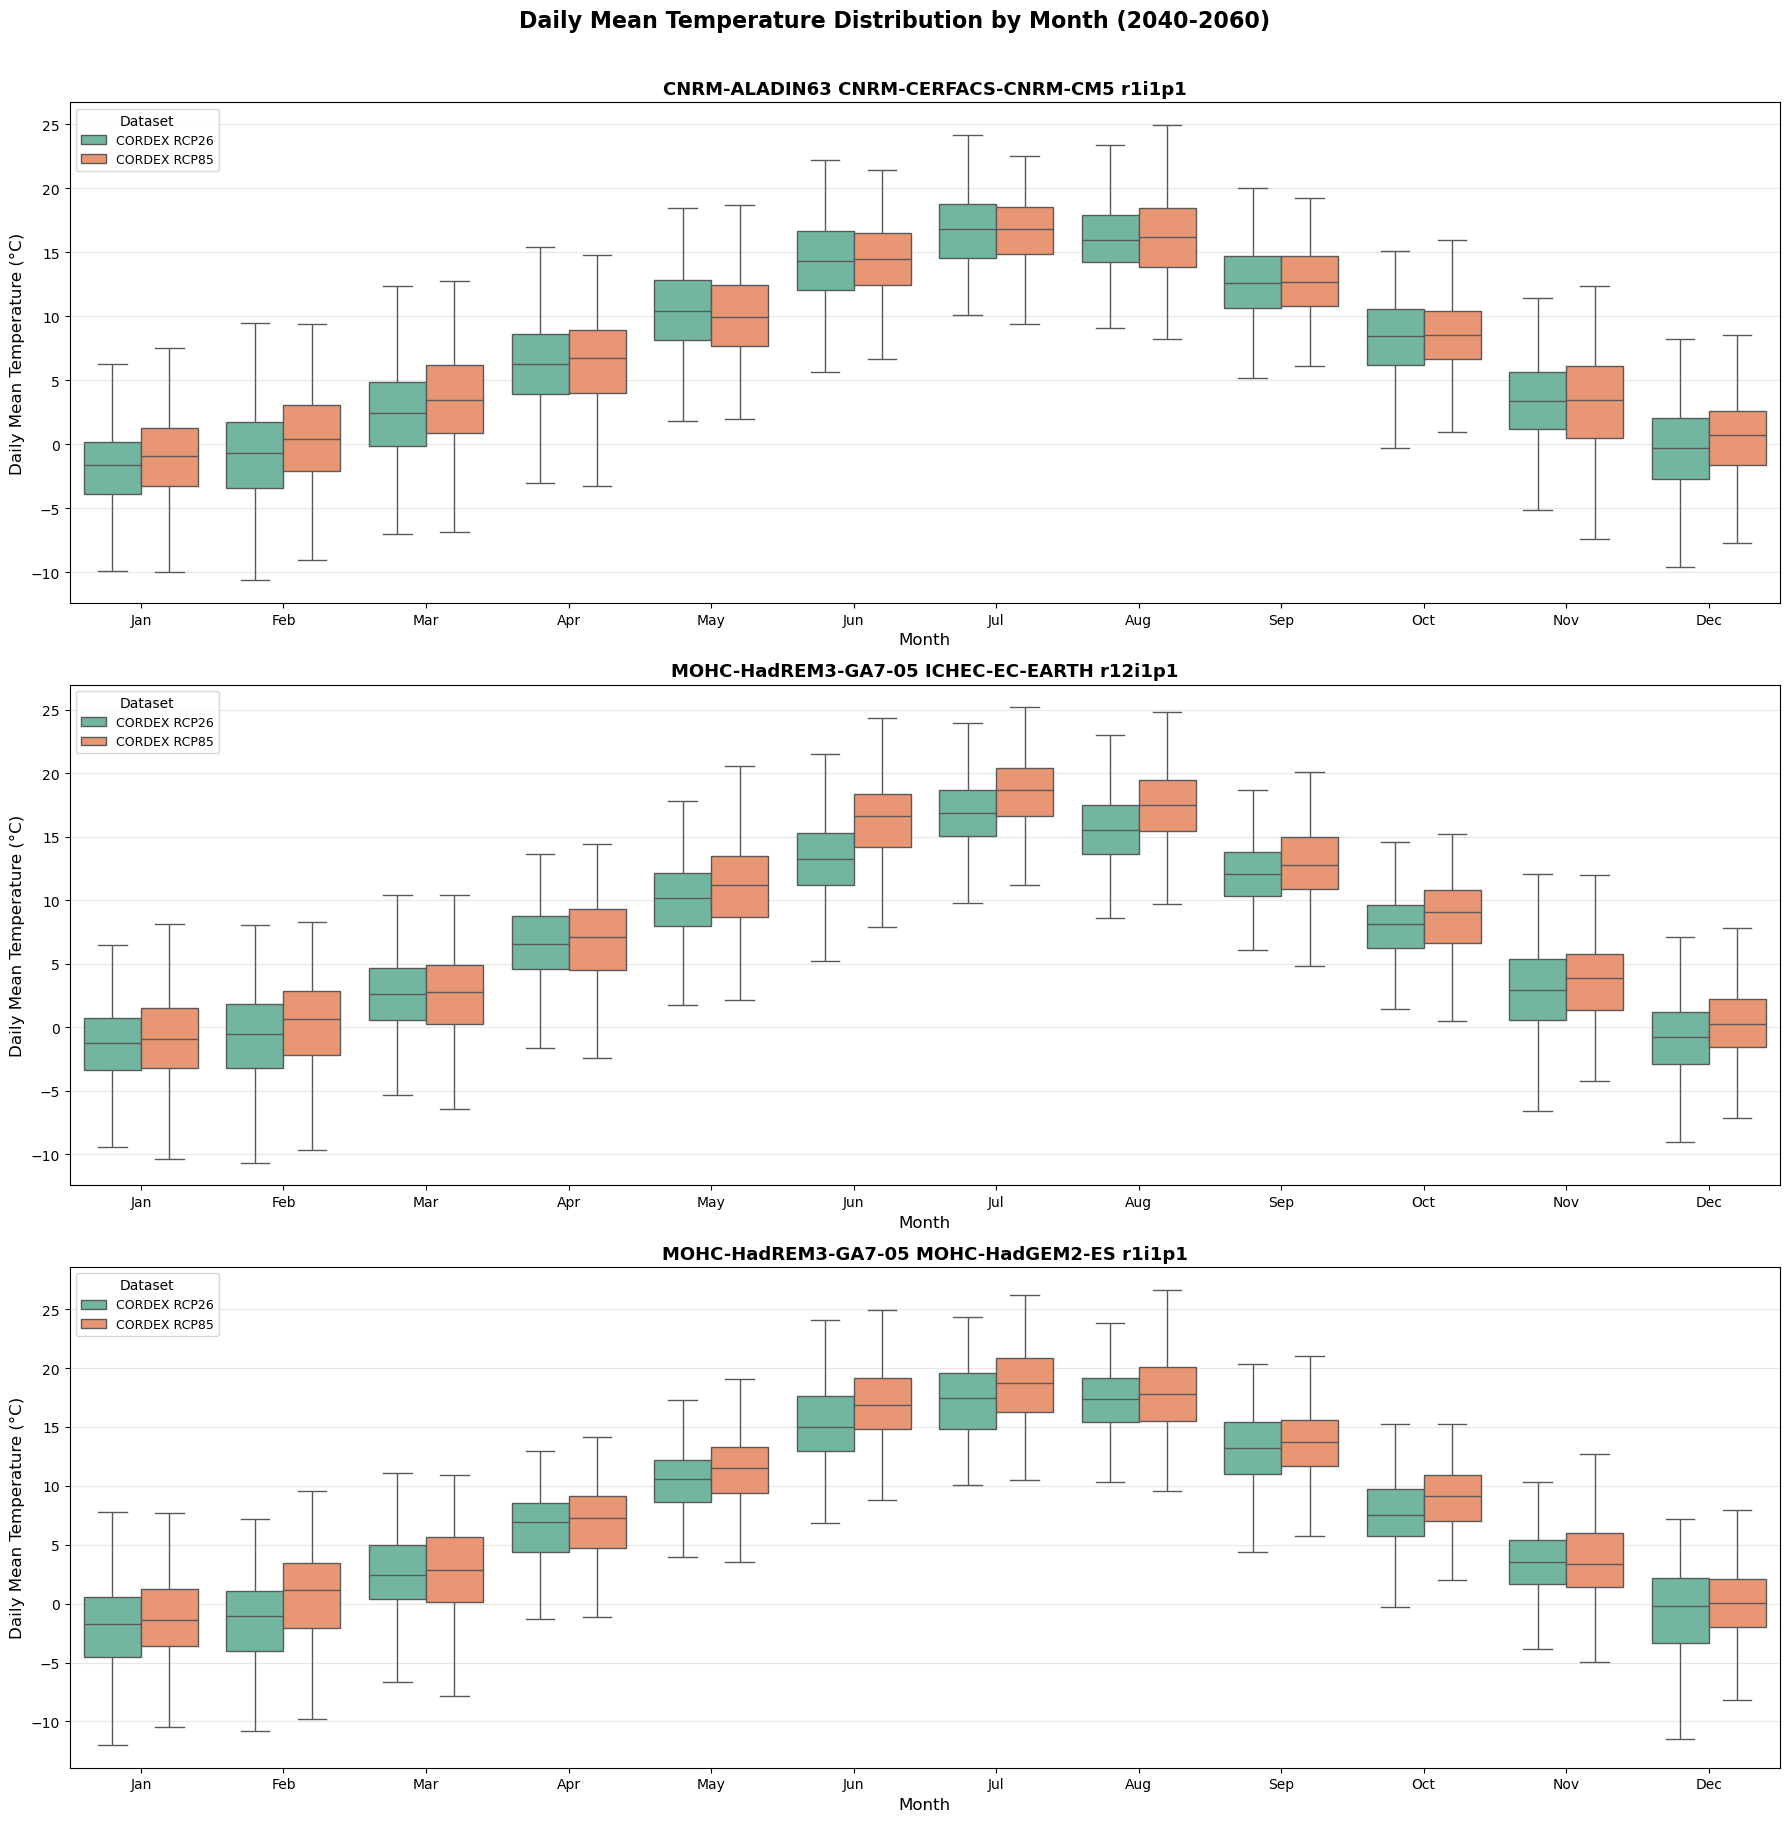

In [21]:
# Prepare data for boxplot: group daily values by month for temperature (2040-2060)
# Keyed by chain so we can split per subplot
data_for_boxplot_tas = {chain: [] for chain in climate_model_chains}

for climate_model_chain in climate_model_chains:
    for scenario in climate_scenarios:
        ds_tas = ds_tas_dict[climate_model_chain][scenario]
        tas_daily_mean = ds_tas.ds_data['tas'].mean(dim=['lat', 'lon'])

        with ProgressBar():
            tas_daily_computed = tas_daily_mean.compute()

        dataset_name = f'CORDEX {scenario.upper()}'

        cordex_df = pd.DataFrame({
            'temperature': tas_daily_computed.values - 273.15,
            'month': tas_daily_computed['time'].dt.month.values,
            'dataset': dataset_name
        })
        data_for_boxplot_tas[climate_model_chain].append(cordex_df)

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(len(climate_model_chains), 1,
                          figsize=(18, 6 * len(climate_model_chains)))

if len(climate_model_chains) == 1:
    axes = [axes]

for idx, climate_model_chain in enumerate(climate_model_chains):
    ax = axes[idx]

    df_chain = pd.concat(data_for_boxplot_tas[climate_model_chain], ignore_index=True)

    sns.boxplot(
        data=df_chain,
        x='month',
        y='temperature',
        hue='dataset',
        ax=ax,
        palette='Set2',
        showfliers=False,
        hue_order=[f'CORDEX {s.upper()}' for s in climate_scenarios]
    )

    ax.set_xlabel('Month', fontsize=12)
    ax.set_ylabel('Daily Mean Temperature (°C)', fontsize=12)
    chain_name = climate_model_chain.replace('_', ' ')
    ax.set_title(f'{chain_name}', fontsize=13, fontweight='bold')
    ax.set_xticklabels(month_names)
    ax.legend(title='Dataset', fontsize=9, title_fontsize=10, loc='upper left')
    ax.grid(True, alpha=0.3, axis='y')

fig.suptitle('Daily Mean Temperature Distribution by Month (2040-2060)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


In [24]:
ds_2t = sel_extent(xr.open_zarr(path_data_processed / "cerra_processed" / "regridded" / "2t.zarr", chunks="auto"), extent=EXTENT_CH).sel(time=slice("1991", "2020"))

In [25]:
path_meteoswiss = Path("/net/atmos/data/MeteoCH_gridded/")
ds_tabsd = xr.open_mfdataset((path_meteoswiss / "ch01" / "TabsD").glob("*.nc"), chunks="auto").sel(time=slice("1991", "2020"))

In [28]:
path_era5 = Path(paths["path_data_cerra"]).parent / "era5_cds"
paths_era5_tas = [p for year in range(1991, 2021) for p in (path_era5 / "processed/v2/tas/mon/native").glob(f"{year}/**/*.nc")]
ds_era5_tas = sel_extent(xr.open_mfdataset(paths_era5_tas, chunks="auto"), EXTENT_CH).sel(time=slice("1991", "2020"))

In [32]:
# Compute spatial means for CERRA and RhiresD (common to all subplots)
cerra_2t_daily_mean = ds_2t['2t'].resample(time="1D").mean(dim="time").mean(dim=['lat', 'lon'])
tabsd_daily_mean = ds_tabsd['TabsD'].mean(dim=['E', 'N'])

# Compute monthly means for CERRA and RhiresD
cerra_2t_monthly_mean = cerra_2t_daily_mean.groupby('time.month').mean()
tabsd_monthly_mean = tabsd_daily_mean.groupby('time.month').mean()
era5_tas_monthly_mean = ds_era5_tas['tas'].mean(dim=['lat', 'lon']).groupby('time.month').mean()
# Compute with progress bar
with ProgressBar():
    cerra_2t_monthly_mean = cerra_2t_monthly_mean.compute()
    tabsd_monthly_mean = tabsd_monthly_mean.compute()
    era5_tas_monthly_mean = era5_tas_monthly_mean.compute()
# Compute monthly means for each climate model chain and scenario
tas_monthly_means = {}
for climate_model_chain in climate_model_chains:
    tas_monthly_means[climate_model_chain] = {}
    for scenario in climate_scenarios:
        ds_tas = ds_tas_dict[climate_model_chain][scenario]
        tas_daily_mean = ds_tas.ds_data['tas'].mean(dim=['lat', 'lon'])
        tas_monthly_mean = tas_daily_mean.groupby('time.month').mean()

        with ProgressBar():
            tas_monthly_means[climate_model_chain][scenario] = tas_monthly_mean.compute()

[########################################] | 100% Completed | 302.92 ms
[########################################] | 100% Completed | 2.22 sms
[########################################] | 100% Completed | 1.13 sms
[########################################] | 100% Completed | 203.13 ms
[########################################] | 100% Completed | 203.50 ms
[########################################] | 100% Completed | 203.36 ms
[########################################] | 100% Completed | 203.23 ms
[########################################] | 100% Completed | 305.44 ms
[########################################] | 100% Completed | 1.11 sms


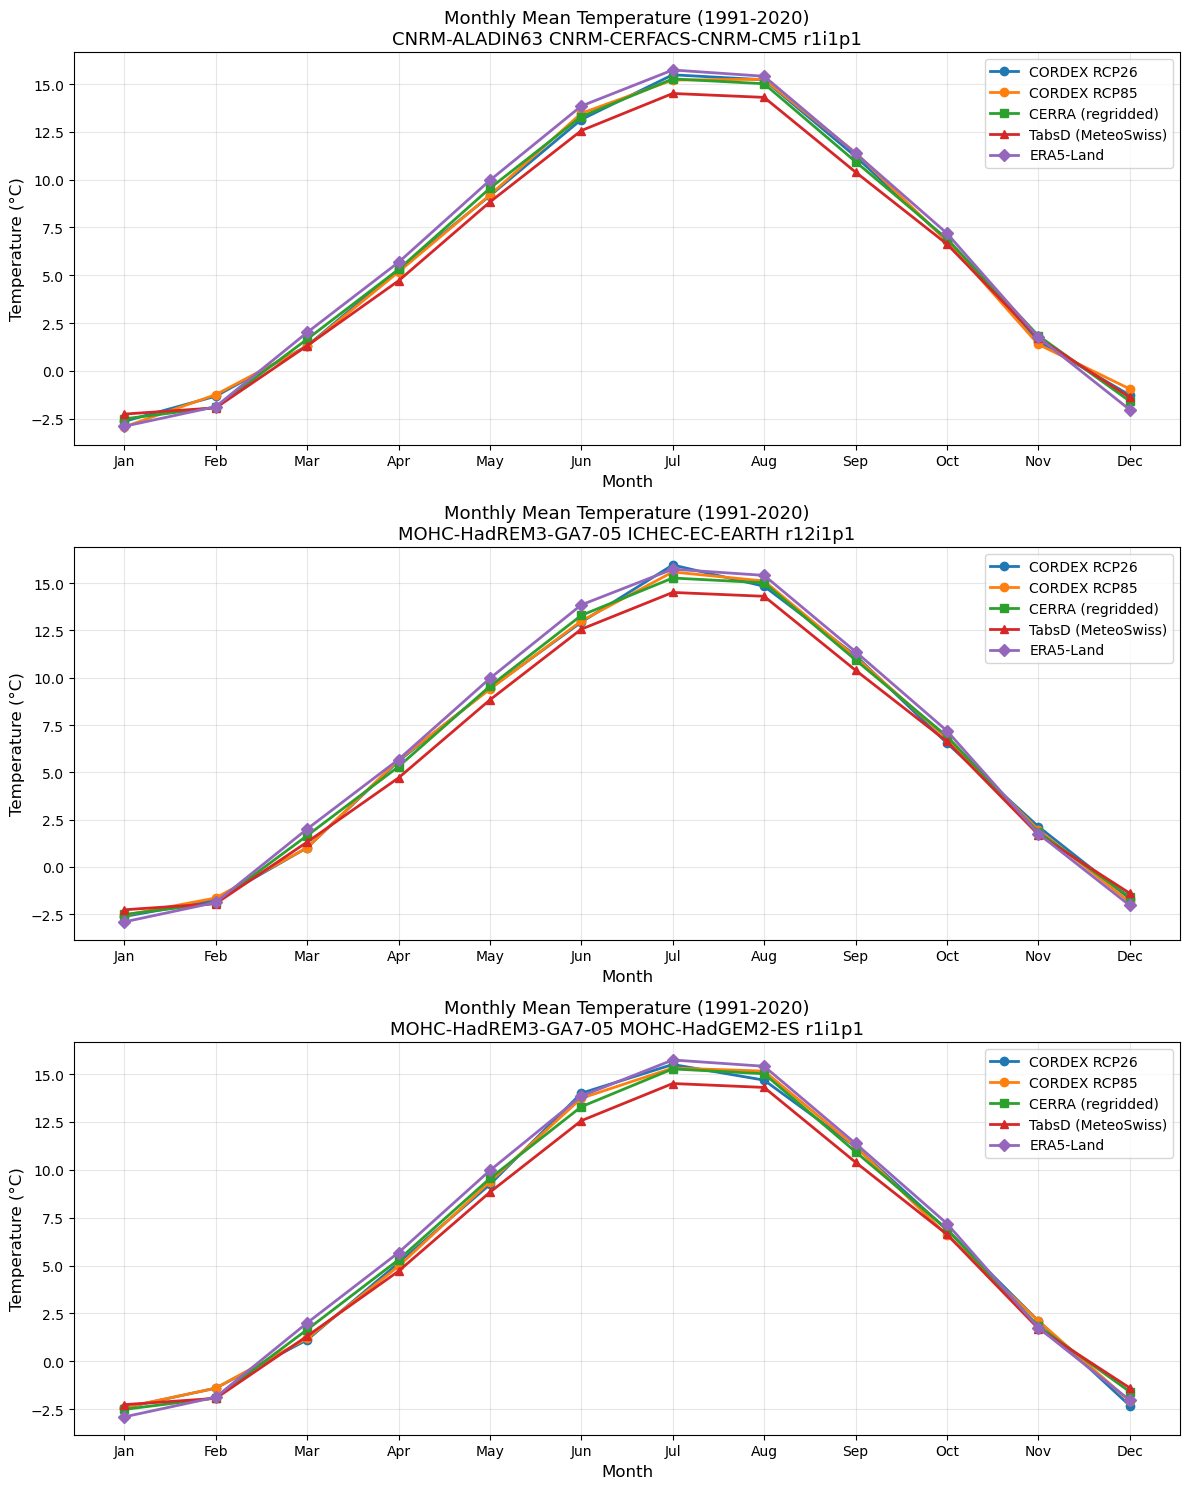

In [33]:
# Create subplots for each climate model chain
fig, axes = plt.subplots(len(climate_model_chains), 1, figsize=(12, 5 * len(climate_model_chains)))

# If only one chain, axes is not a list
if len(climate_model_chains) == 1:
    axes = [axes]

for idx, climate_model_chain in enumerate(climate_model_chains):
    ax = axes[idx]

    # Plot the monthly means for each scenario
    for scenario in climate_scenarios:
        ax.plot(tas_monthly_means[climate_model_chain][scenario].month,
                tas_monthly_means[climate_model_chain][scenario] - 273.15,
                marker='o', label=f'CORDEX {scenario.upper()}', linewidth=2, markersize=6)

    ax.plot(cerra_2t_monthly_mean.month, cerra_2t_monthly_mean - 273.15,
            marker='s', label='CERRA (regridded)', linewidth=2, markersize=6)
    ax.plot(tabsd_monthly_mean.month, tabsd_monthly_mean,
            marker='^', label='TabsD (MeteoSwiss)', linewidth=2, markersize=6)
    ax.plot(era5_tas_monthly_mean.month, era5_tas_monthly_mean - 273.15,
            marker='D', label='ERA5-Land', linewidth=2, markersize=6)

    ax.set_xlabel('Month', fontsize=12)
    ax.set_ylabel('Temperature (°C)', fontsize=12)

    # Format the chain name for the title
    chain_name = climate_model_chain.replace('_', ' ')
    ax.set_title(f'Monthly Mean Temperature (1991-2020)\n{chain_name}', fontsize=13)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                        'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
# Prepare data for boxplot: group daily values by month
data_for_boxplot = []

# Process CERRA data
cerra_2t_daily = ds_2t['2t'].resample(time="1D").mean(dim="time").mean(dim=['lat', 'lon'])
cerra_2t_daily_computed = cerra_2t_daily.compute()
cerra_df = pd.DataFrame({
    'temperature': cerra_2t_daily_computed.values - 273.15,
    'month': cerra_2t_daily_computed['time'].dt.month.values,
    'dataset': 'CERRA'
})
data_for_boxplot.append(cerra_df)

# Process TabsD data
tabsd_daily_computed = tabsd_daily_mean.compute()
tabsd_df = pd.DataFrame({
    'temperature': tabsd_daily_computed.values,
    'month': tabsd_daily_computed['time'].dt.month.values,
    'dataset': 'TabsD (MeteoSwiss)'
})
data_for_boxplot.append(tabsd_df)

# Process CORDEX data for each climate model chain and scenario
for climate_model_chain in climate_model_chains:
    for scenario in climate_scenarios:
        ds_tas = ds_tas_dict[climate_model_chain][scenario]
        tas_daily_mean = ds_tas.ds_data['tas'].mean(dim=['lat', 'lon'])

        with ProgressBar():
            tas_daily_computed = tas_daily_mean.compute()

        # Create short name for dataset
        chain_short = climate_model_chain.split('_')[0]
        dataset_name = f'{chain_short} {scenario.upper()}'

        cordex_df = pd.DataFrame({
            'temperature': tas_daily_computed.values - 273.15,
            'month': tas_daily_computed['time'].dt.month.values,
            'dataset': dataset_name
        })
        data_for_boxplot.append(cordex_df)

# Combine all dataframes
df_combined = pd.concat(data_for_boxplot, ignore_index=True)

print(f"Data prepared: {df_combined.shape[0]} daily values across {df_combined['dataset'].nunique()} datasets")
print(f"Datasets: {df_combined['dataset'].unique()}")

ValueError: Per-column arrays must each be 1-dimensional

In [ ]:
# Create boxplot with datasets side by side for each month
fig, ax = plt.subplots(figsize=(18, 8))

# Define month names for labels
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Create boxplot
sns.boxplot(
    data=df_combined,
    x='month',
    y='temperature',
    hue='dataset',
    ax=ax,
    palette='Set2',
    showfliers=False  # Hide outliers for cleaner visualization
)

ax.set_xlabel('Month', fontsize=14)
ax.set_ylabel('Daily Mean Temperature (°C)', fontsize=14)
ax.set_title('Daily Mean Temperature Distribution by Month (1991-2020)', fontsize=16, fontweight='bold')
ax.set_xticklabels(month_names)
ax.legend(title='Dataset', fontsize=10, title_fontsize=11, loc='upper left')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()